# Coronagraph (SOHO/LASCO) features, path (i) (not built)

**The question:** do generic coronagraph brightening numbers, fed straight into the speed models,
improve the forecast?

**Data:** LASCO C2 (hourly) and C3 (2-hourly) browse images, 2016-10 → 2026-10, the same product as
live (`training.pull_lasco_images`). Each image becomes 12 position-angle sectors × 2 rings of median
grey levels; each cell is compared with its own median over the previous 6 h (the brightening);
per image the share of brightened outer sectors, the max and the mean
(`feature_engineering.coronagraph`). Per t0, the largest value over the last 6 / 24 / 72 h of images
taken by t0 − 30 min (`feature_engineering.windows`).

**The test** (`python -m training.coronagraph_features`): five feature sets added to the hybrid's
trees, two single terms added to the linear model. Six yearly walk-forward folds (2019-10 → 2025-10);
score: per-run mean TIMSE / persistence, geometric mean over folds; also on CME runs and the rest.
The eval year is not used.

**Keep rule (set before running):** more than 1% better on the six-fold score, winning at least
4 of 6 folds, CME runs better and other runs not worse by more than 0.5%.

1. The signals
2. Scores
3. By fold
4. CME runs and the rest
5. Findings

## 1. The signals around the May 2024 storm (halo CMEs from 8 May, arrival 10 May)

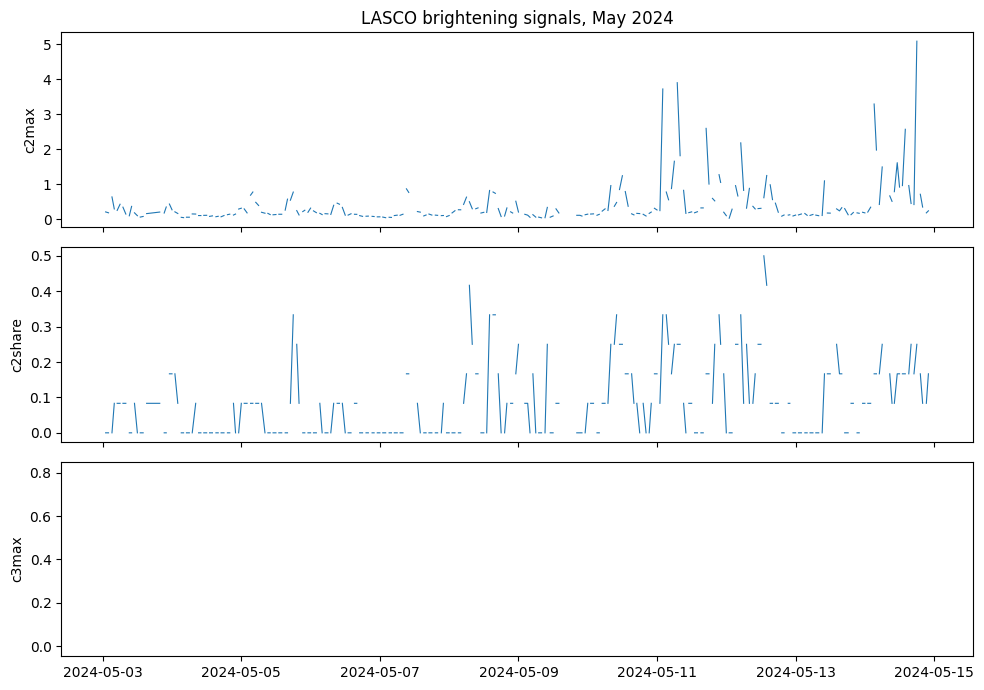

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import coronagraph_features as cf

signals = cf.load_signals()
window = signals.loc["2024-05-03":"2024-05-14"]
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, s in zip(axes, ("c2max", "c2share", "c3max"), strict=True):
    ax.plot(window.index, window[s], lw=0.8)
    ax.set_ylabel(s)
axes[0].set_title("LASCO brightening signals, May 2024")
plt.tight_layout()

## 2. Scores

In [2]:
df = pd.read_csv(cf.EXPERIMENTS / "coronagraph_features.csv").set_index("fold")


def geo(c):
    return float(np.exp(np.log(df[c]).mean()))


rows = {}
for name in cf.variant_names()[1:]:
    ref = "hybrid shipped" if name.startswith("hybrid") else "linear shipped"
    rows[name] = {"score": geo(name), "vs shipped": geo(name) / geo(ref) - 1,
                  "folds won": int((df[name] < df[ref]).sum()),
                  "CME runs": geo(f"{name} cme") - 1, "other runs": geo(f"{name} other") - 1}
for ref in ("hybrid shipped", "linear shipped"):
    rows[ref] = {"score": geo(ref)}
summary = pd.DataFrame(rows).T.sort_values("score")
summary["keep"] = ((summary["vs shipped"] < -0.01) & (summary["folds won"] >= 4)
                   & (summary["CME runs"] < 0) & (summary["other runs"] < 0.005))
with pd.option_context("display.float_format", "{:.4f}".format):
    display(summary)

,score,vs shipped,folds won,CME runs,other runs,keep
hybrid + all c2,0.4175,-0.0036,3.0000,-0.0328,0.0105,False
hybrid + c2 max + share,0.4175,-0.0035,3.0000,-0.0276,0.0067,False
hybrid shipped,0.4190,NaN,NaN,NaN,NaN,False
hybrid + c2 max + mean,0.4199,0.0022,2.0000,-0.0228,0.0127,False
hybrid + c2 + c3 max,0.4224,0.0081,2.0000,-0.0156,0.0141,False
hybrid + c2 max,0.4225,0.0084,2.0000,-0.0033,0.0114,False
linear shipped,0.4256,NaN,NaN,NaN,NaN,False
linear + c2max_max_24h,0.4269,0.0031,2.0000,0.0023,0.0073,False
linear + c2max_max_72h,0.4270,0.0033,0.0000,0.0181,0.0041,False


## 3. By fold (% change against the shipped model)

fold,2019-10,2020-10,2021-10,2022-10,2023-10,2024-10
hybrid + c2 max,0.41,3.11,1.13,-0.10,-0.31,0.82
hybrid + c2 max + mean,-0.84,2.97,1.76,0.14,-2.80,0.20
hybrid + c2 + c3 max,-0.68,4.16,1.08,0.46,-0.10,0.01
hybrid + c2 max + share,-1.94,2.19,-1.82,1.92,-2.33,0.00
hybrid + all c2,-1.70,2.69,-0.23,0.00,-3.14,0.31
linear + c2max_max_24h,1.02,0.21,0.31,-0.07,-0.55,0.95
linear + c2max_max_72h,1.12,0.01,0.34,0.16,0.18,0.19


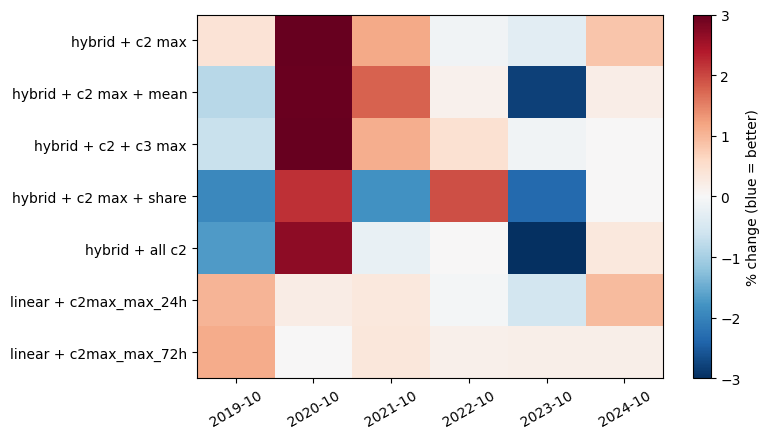

In [3]:
change = pd.DataFrame({
    n: 100 * (df[n] / df["hybrid shipped" if n.startswith("hybrid") else "linear shipped"] - 1)
    for n in cf.variant_names()[1:]})
fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(change.T.to_numpy(), cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
ax.set_yticks(range(change.shape[1]), change.columns)
ax.set_xticks(range(change.shape[0]), change.index, rotation=30)
plt.colorbar(im, label="% change (blue = better)")
plt.tight_layout()
display(change.T.round(2))

## 4. CME runs and the rest (% change against the shipped model, per fold)

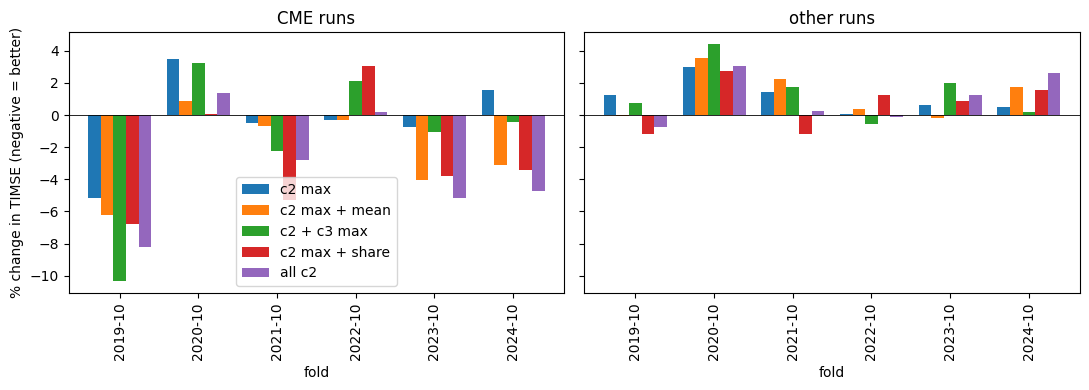

In [4]:
hyb = [n for n in cf.variant_names()[1:] if n.startswith("hybrid")]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, part in zip(axes, ("cme", "other"), strict=True):
    tab = pd.DataFrame({n.removeprefix("hybrid + "): 100 * (df[f"{n} {part}"] - 1) for n in hyb})
    tab.plot.bar(ax=ax, width=0.8, legend=part == "cme")
    ax.axhline(0, color="k", lw=0.6)
    ax.set_title(f"{'CME' if part == 'cme' else 'other'} runs")
    ax.set_ylabel("% change in TIMSE (negative = better)")
plt.tight_layout()

## 5. Findings

- **Not built: nothing passes the bar.** The best sets (all C2 features; C2 max + share) gain 0.35% on the hybrid in 3 of 6 folds, against a bar of 1% and 4 of 6. Both linear-model terms are slightly worse.
- **The signal carries CME information.** The hybrid with all C2 features gains 3.3% on CME runs (up to 8.2% in the 2019 fold).
- **But an active Sun brightens everywhere.** In section 1, `c2max` sits above its all-time 90th percentile (0.37) on most days of 3–14 May 2024. Its largest values (3.9 on 11 May, 5.1 on 14 May) come after the halo CMEs of 8–9 May that drove the storm, not at them. A brightening alone doesn't say which CME is heading for Earth.
- **The cost is on quiet runs:** +1.0% on the other 82% of runs. Most brightenings are limb CMEs and streamer changes that never reach L1, and with about 100 Earth-directed CMEs in nine years the trees can't learn from the summaries alone which ones matter.
- **C3 adds nothing** over C2, as the separation check against the CDAW catalogue suggested (AUC 0.53–0.68 for C3, 0.92 for C2 max).
- **Next:** path (ii), a CME detector trained on the CDAW labels with physical constraints, whose output stays quiet unless a brightening looks Earth-directed. The data and feature code here are its inputs ([docs/coronagraph.md](../../docs/coronagraph.md)).